In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
def bike_sharing_dataset():

    bike_sharing = fetch_ucirepo(id=275)

    # data (as pandas dataframes) 
    X = bike_sharing.data.features 
    y = bike_sharing.data.targets 

    return X, y, bike_sharing

In [3]:
X, y, bike_sharing = bike_sharing_dataset()

In [4]:
import pandas as pd

# Dataset metadata and additional information : List[dict] -> Dataframe
metadata = pd.Series(bike_sharing.metadata).to_frame(
    name="Value"
)

print("Total number of metadata entries:", len(metadata))
display(metadata.head())

Total number of metadata entries: 22


,Value
uci_id,275
name,Bike Sharing
repository_url,https://archive.ics.uci.edu/dataset/275/bike+s...
data_url,https://archive.ics.uci.edu/static/public/275/...
abstract,This dataset contains the hourly and daily cou...


In [5]:
# changing the pandas default setting to adjust the table for full view
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

# variable/dataset information
display(bike_sharing.variables)

,name,role,type,demographic,description,units,missing_values
0,instant,ID,Integer,None,record index,None,no
1,dteday,Feature,Date,None,date,None,no
2,season,Feature,Categorical,None,"1:winter, 2:spring, 3:summer, 4:fall",None,no
3,yr,Feature,Categorical,None,"year (0: 2011, 1: 2012)",None,no
4,mnth,Feature,Categorical,None,month (1 to 12),None,no
5,hr,Feature,Categorical,None,hour (0 to 23),None,no
6,holiday,Feature,Binary,None,weather day is holiday or not (extracted from http://dchr.dc.gov/page/holiday-schedule),None,no
7,weekday,Feature,Categorical,None,day of the week,None,no
8,workingday,Feature,Binary,None,"if day is neither weekend nor holiday is 1, otherwise is 0",None,no
9,weathersit,Feature,Categorical,None,"- 1: Clear, Few clouds, Partly cloudy, Partly cloudy",None,no


In [6]:
display(X.sample(5))

,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed
10359,2012-03-12,1,1,3,18,0,1,1,2,0.60,0.6212,0.43,0.1940
10822,2012-04-01,2,1,4,1,0,0,0,2,0.36,0.3485,0.76,0.1642
12090,2012-05-23,2,1,5,23,0,3,1,1,0.60,0.5606,0.83,0.1343
4896,2011-07-27,3,0,7,22,0,3,1,1,0.72,0.6667,0.48,0.0000
16666,2012-12-02,4,1,12,5,0,0,0,2,0.26,0.3030,0.93,0.0000


In [7]:
print("X shape:", X.shape)
print("X columns:", X.columns.tolist())

print("y shape:", y.shape)
print("y columns:", y.columns.tolist())

X shape: (17379, 13)
X columns: ['dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']
y shape: (17379, 1)
y columns: ['cnt']


In [8]:
X.drop(columns=["dteday"], inplace=True)
X.head()
# dropping dteday [date] doesn't value in training the model

,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed
0,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0
1,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0
2,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0
3,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0
4,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0


In [9]:
display(y.sample(5))

,cnt
8069,6
8910,3
9434,38
7677,162
6311,369


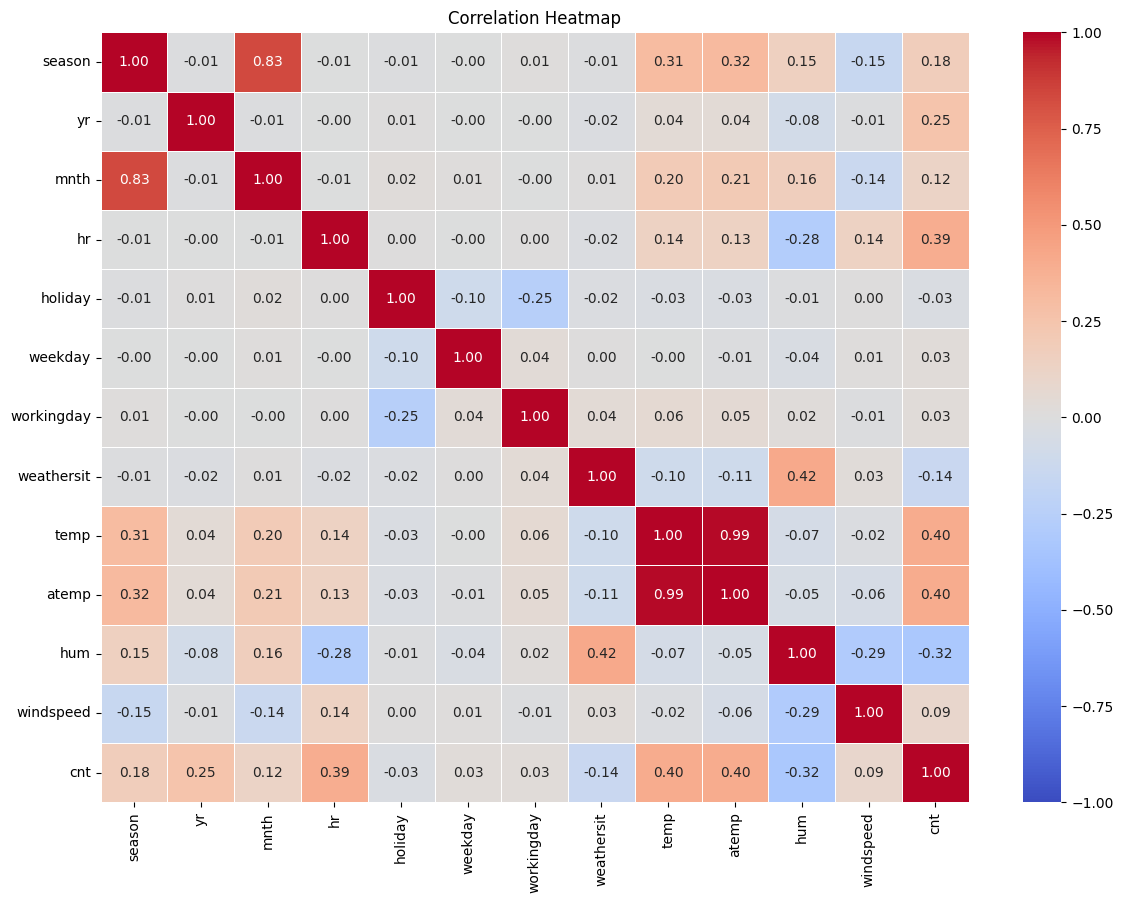

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# joining X - features and y - targets to create complete dataframe
df = X.join(y)

# Select numerical columns
corr = df.select_dtypes(include='number').corr()

# Plot correlation heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap')
plt.show()

In [11]:
display(df.sample(6))

,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
7206,4,0,11,21,0,2,1,1,0.36,0.3788,0.81,0.0000,127
15560,4,1,10,13,0,1,1,2,0.56,0.5303,0.88,0.2239,146
6416,4,0,9,22,0,4,1,1,0.56,0.5303,0.68,0.0000,175
8192,4,0,12,0,0,2,1,1,0.22,0.2727,0.80,0.0000,17
8019,4,0,12,19,0,1,1,2,0.46,0.4545,0.77,0.0000,308
11420,2,1,4,1,0,4,1,2,0.48,0.4697,0.48,0.0896,23


In [ ]:
from sklearn.model_selection import train_test_split

def get_bike_sharing():

    X, y, _ = bike_sharing_dataset()
    
    return train_test_split(
        X,  y.squeeze(),      # Convert single-column target DataFrame to Series
        test_size=0.2,       # 20% testing, 80% training
        random_state=42,     # Reproducibility
        shuffle=True
    )

In [ ]:
# to reset the pandas default option settings
pd.reset_option("all")